# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 프로젝트 질문과 계산 기준 (코드 실행 전 정의)

## 1. 프로젝트 질문
### 분석 질문
1. 카테고리별 completed 주문 기준 구매 금액과 비중은 어떻게 다른가?
2. 월별 completed 주문 기준 금액과 고유 주문 수는 어떻게 변하는가?
3. completed 주문 기준 구매 금액이 높은 고객은 어떤 구매 패턴을 보이는가?

### 분석 범위
금액성 분석은 `order_status == "completed"`인 주문 상세만 포함했다. 주문 상태별 주문 수 비교에만 전체 주문 데이터를 사용했다. 주문 상세 행 수와 주문 수는 구분하고, 주문 수는 고유 `order_id` 기준으로 계산했다.

### 사용할 데이터와 지표
`customers`, `products`, `orders`, `order_items`를 사용했다. 주요 지표는 `line_total` 합계, 판매 수량, 고유 주문 수, 평균 주문 금액, 카테고리별 금액 비중이다.

### 계산 기준
- `order_status == "completed"` 적용 여부: 예. 금액 분석은 completed 주문 474개 상세 행에 한정했다.
- `line_total = quantity × unit_price` 확인 여부: 예. 764개 행에서 불일치 0건으로 확인했다.

### 완료 기준
PK 결측·중복과 FK 미매칭이 각각 0건이고, 병합 검증·line_total·날짜·개인정보 검증이 통과해야 한다. 또한 completed source 금액과 카테고리·월·고객별 금액 합계가 모두 일치해야 한다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)


Python 실행 파일: c:\Users\ojh23\Documents\projects\llm-data-analysis-course\.venv\Scripts\python.exe
프로젝트 루트: C:\Users\ojh23\Documents\projects\llm-data-analysis-course
원본 데이터 폴더: C:\Users\ojh23\Documents\projects\llm-data-analysis-course\data\raw
보고서 폴더: C:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [3]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [4]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [5]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\Users\ojh23\Documents\projects\llm-data-analysis-course\data\processed\customers_clean.csv OK
C:\Users\ojh23\Documents\projects\llm-data-analysis-course\data\processed\products_clean.csv OK
C:\Users\ojh23\Documents\projects\llm-data-analysis-course\data\processed\orders_clean.csv OK
C:\Users\ojh23\Documents\projects\llm-data-analysis-course\data\processed\order_items_clean.csv OK


## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [6]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [7]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [8]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [9]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [10]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [11]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [12]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 141
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 438
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1089


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [13]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


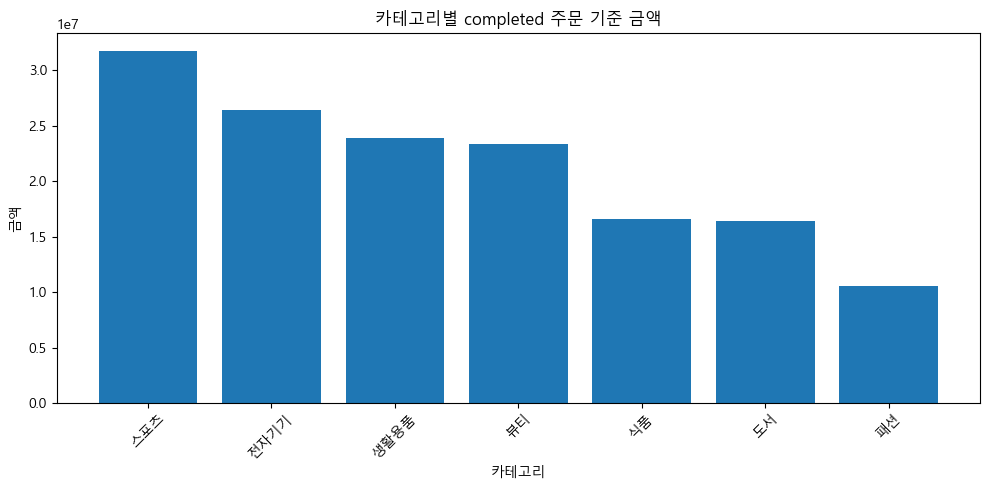

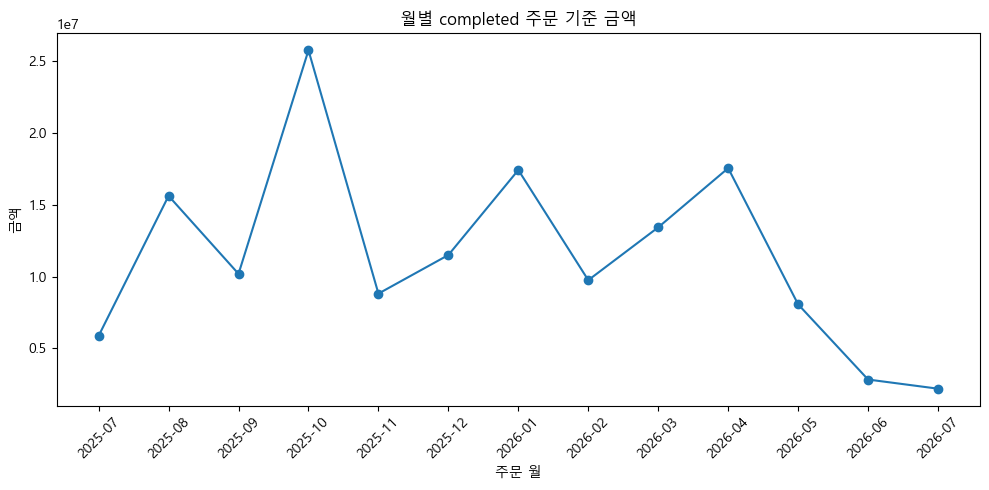

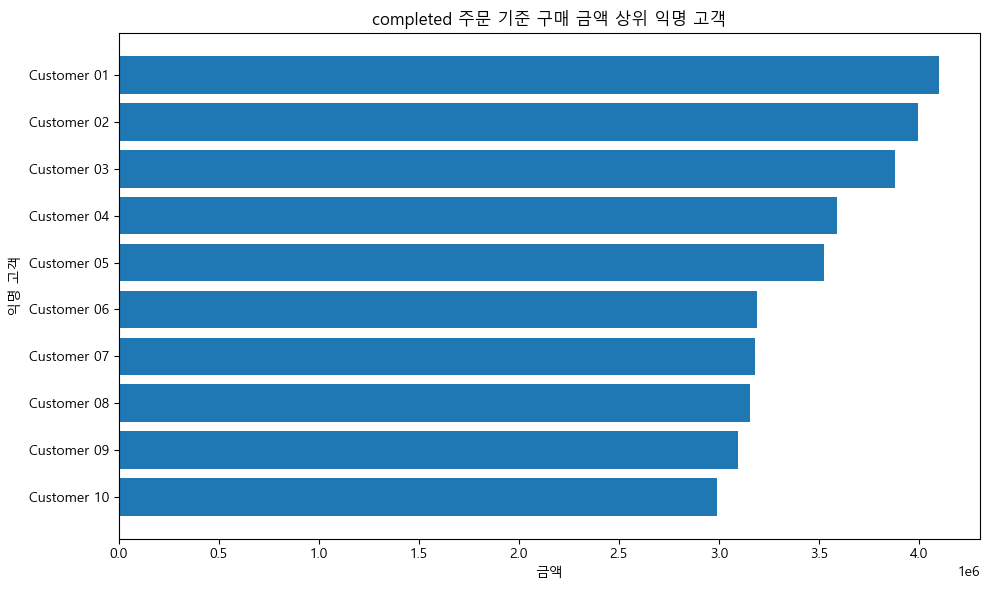

ch08_category_sales.png True 32631
ch08_monthly_sales.png True 61719
ch08_top_customers.png True 44039


In [14]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [15]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: C:\Users\ojh23\Documents\projects\llm-data-analysis-course\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150     

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [16]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


WindowsPath('C:/Users/ojh23/Documents/projects/llm-data-analysis-course/reports/ch08_midterm_report.md')

## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [17]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [19]:
# 18. 실습 과제: 핵심 결과와 최종 Evidence를 다시 확인합니다.

# 1) 분석 질문에 맞는 핵심 EDA 결과 3개 요약
category_top = category_sales.sort_values("total_sales", ascending=False).iloc[0]
monthly_peak = monthly_sales.sort_values("total_sales", ascending=False).iloc[0]
monthly_low = monthly_sales.sort_values("total_sales", ascending=True).iloc[0]
customer_top = customer_sales_public.sort_values("total_sales", ascending=False).iloc[0]

exercise_eda_summary = pd.DataFrame([
    {
        "analysis": "카테고리별 completed 금액",
        "observation": f"{category_top['category']}가 {category_top['total_sales']:,.0f}원으로 가장 큼 ({category_top['sales_ratio']:.2f}%)",
        "limitation": "금액만으로 판매량·단가의 영향이나 수익성을 구분할 수 없음",
    },
    {
        "analysis": "월별 completed 금액",
        "observation": f"최고 {monthly_peak['order_month']}: {monthly_peak['total_sales']:,.0f}원 / 최저 {monthly_low['order_month']}: {monthly_low['total_sales']:,.0f}원",
        "limitation": "월별 주문 수 차이를 함께 봐야 하며 원인을 단정할 수 없음",
    },
    {
        "analysis": "고객별 completed 구매 금액",
        "observation": f"익명 상위 고객 {customer_top['customer_label']}: {customer_top['total_sales']:,.0f}원",
        "limitation": "반복 구매와 일회성 고액 구매를 추가로 구분해야 함",
    },
])
display(exercise_eda_summary)

# 2) 대표 그래프에 사용한 원본 집계값 확인
completed_source_total = float(
    total_consistency.loc[total_consistency["source"].eq("completed_source"), "amount"].iloc[0]
)
graph_source_checks = pd.DataFrame([
    {
        "graph": "카테고리별 금액",
        "aggregate_total": float(category_sales["total_sales"].sum()),
        "matches_completed_source": bool(np.isclose(category_sales["total_sales"].sum(), completed_source_total)),
        "figure_exists": (FIGURE_DIR / "ch08_category_sales.png").exists(),
    },
    {
        "graph": "월별 금액",
        "aggregate_total": float(monthly_sales["total_sales"].sum()),
        "matches_completed_source": bool(np.isclose(monthly_sales["total_sales"].sum(), completed_source_total)),
        "figure_exists": (FIGURE_DIR / "ch08_monthly_sales.png").exists(),
    },
])
display(graph_source_checks)
assert graph_source_checks["matches_completed_source"].all()
assert graph_source_checks["figure_exists"].all()

# 3) source/category/month/customer 총합 교차 검증
display(total_consistency[["source", "amount", "difference_from_completed", "status"]])
assert total_consistency["matches_completed"].all()

# 4) 공개 고객 CSV 개인정보 검사
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")
forbidden_public_columns = sorted(FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns))
privacy_evidence = pd.DataFrame([{
    "public_columns": ", ".join(saved_customer.columns),
    "customer_id_included": "customer_id" in saved_customer.columns,
    "forbidden_columns": ", ".join(forbidden_public_columns),
    "status": "PASS" if not forbidden_public_columns and "customer_id" not in saved_customer.columns else "FAIL",
}])
display(privacy_evidence)
assert privacy_evidence.loc[0, "status"] == "PASS"

# 5) Notebook 전체 파이프라인 재실행 결과 및 핵심 산출물 확인
reproduced_validation = project_result["project_validation"]
display(reproduced_validation)
assert reproduced_validation["status"].eq("PASS").all()
assert all(path.exists() and path.stat().st_size > 0 for path in expected_outputs)
print("실습 과제 검증: PASS")
print("CLI 재실행은 프로젝트 루트에서 python scripts/run_midterm_project.py로 수행했고, 터미널 결과는 images/step06_reproduce.png에 첨부했습니다.")


,analysis,observation,limitation
0,카테고리별 completed 금액,"스포츠가 31,743,000원으로 가장 큼 (21.31%)",금액만으로 판매량·단가의 영향이나 수익성을 구분할 수 없음
1,월별 completed 금액,"최고 2025-10: 25,766,000원 / 최저 2026-07: 2,188,000원",월별 주문 수 차이를 함께 봐야 하며 원인을 단정할 수 없음
2,고객별 completed 구매 금액,"익명 상위 고객 Customer 01: 4,100,000원",반복 구매와 일회성 고액 구매를 추가로 구분해야 함


,graph,aggregate_total,matches_completed_source,figure_exists
0,카테고리별 금액,148990000.0,True,True
1,월별 금액,148990000.0,True,True


,source,amount,difference_from_completed,status
0,completed_source,148990000.0,0.0,PASS
1,category,148990000.0,0.0,PASS
2,monthly,148990000.0,0.0,PASS
3,customer,148990000.0,0.0,PASS


,public_columns,customer_id_included,forbidden_columns,status
0,"customer_label, city, order_count, total_sales...",False,,PASS


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


실습 과제 검증: PASS
CLI 재실행은 프로젝트 루트에서 python scripts/run_midterm_project.py로 수행했고, 터미널 결과는 images/step06_reproduce.png에 첨부했습니다.


## 제출 정보
- 이름: 오병희
- GitHub ID: OBHAR
- 작성일: 2026-10-29
- 최종 Notebook URL: https://github.com/OBHAR/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb

## 2. 입력 데이터와 전처리 검증

![원본 데이터와 전처리 전후 검증](images/step02_data_validation.png)
- 사용 원본 파일: `data/raw/customers.csv`, `products.csv`, `orders.csv`, `order_items.csv`
- shape: customers (150, 6), products (100, 4), orders (300, 5), order_items (764, 5)
- 핵심 결측/중복 결과: 네 데이터 모두 결측 0건, 전체 행 중복 0건
- 전처리 전후 변화: 행 수 변화 없음. customers 150→150, products 100→100, orders 300→300, order_items 764→764. 전처리 결과에서 orders 열은 5→7, order_items 열은 5→6으로 늘었다.

### 나의 해석과 판단
전처리 과정에서 관측 행은 제거되지 않았다. `orders`와 `order_items`의 열 증가는 분석에 필요한 파생·정리 열이 추가된 결과로 보이며, 행 수 보존 여부는 전처리 비교표로 확인했다. 원본 파일을 직접 수정하지 않고 전처리 결과를 별도 저장했다.

### 한계와 추가 확인 사항
행 수가 유지된 사실만으로 값의 정합성이 보장되지는 않는다. 따라서 PK/FK, 날짜 변환, `line_total` 계산 관계를 별도로 검증했다. 전처리에서 추가된 열의 의미는 생성 코드와 함께 확인해야 한다.

## 3. PK/FK·병합 검증
### PK 결과
- 결측: 네 PK 모두 0건 (`customer_id`, `product_id`, `order_id`, `order_item_id`)
- 중복: 네 PK 모두 0건
- PASS/FAIL: PASS

### FK 결과
- 미매칭: `orders.customer_id`→customers, `order_items.order_id`→orders, `order_items.product_id`→products 모두 0건
- PASS/FAIL: PASS

### 병합 결과
- validate 관계: 상세-주문 `many_to_one`, 상세-상품 `many_to_one`, 고객 집계-고객 `one_to_one`
- 병합 전 행 수: 순서대로 764, 474, 100
- 병합 후 행 수: 순서대로 764, 474, 100
- 미매칭: 각 0건
- PASS/FAIL: PASS

### 나의 해석과 판단
각 병합에서 지정한 관계가 성립했고 행 수가 보존되었으며 미매칭 행도 없었다. 특히 `many_to_one` 검증은 오른쪽 테이블의 키 중복으로 상세 행이 늘어나는 문제를 방지한다. 상품 병합 단계의 474행은 completed 주문 상세 분석 범위다.

## 4. 핵심 EDA 결과
### 결과 1: 카테고리별 completed 주문 금액
- 수치/표: 스포츠 31,743,000원(21.31%), 전자기기 26,400,000원(17.72%), 생활용품 23,915,000원(16.05%), 뷰티 23,383,000원(15.69%), 식품 16,573,000원(11.12%), 도서 16,389,000원(11.00%), 패션 10,587,000원(7.11%). 총합 148,990,000원.
- 결과 관찰: 스포츠 금액이 가장 크고 패션이 가장 작다.
- 나의 해석과 판단: 현재 completed 주문 금액에서 스포츠 카테고리의 비중이 상대적으로 크다.
- 업무·분석적 의미: 카테고리별 판매 수량과 단가를 나누어 확인할 우선순위를 정할 수 있다.
- 한계: 금액 차이만으로 고객 선호나 수익성을 판단할 수 없다.

### 결과 2: 월별 completed 주문 금액과 주문 수
- 수치/표: 2025-07부터 2026-07까지 13개월 분석. 금액 최고는 2025-10의 25,766,000원(고유 주문 26건), 최저는 2026-07의 2,188,000원(고유 주문 2건). 전체 월 합계는 148,990,000원, 주문 수 합계는 184건.
- 결과 관찰: 월별 금액과 주문 수가 변동하며, 두 값 모두 2025-10에 가장 높다. 2026-07은 관측 기간 내 가장 낮다.
- 나의 해석과 판단: 월별 금액 변화는 주문 건수와 평균 주문 금액을 함께 살펴야 해석할 수 있다.
- 업무·분석적 의미: 월별 추이를 모니터링하고 변동이 큰 달의 주문 수·객단가를 후속 점검할 수 있다.
- 한계: 마지막 달은 주문이 2건이어서 다른 달과 직접 비교하기 어렵고, 프로모션이나 계절성이 원인이라고 단정할 수 없다.

### 결과 3: 고객별 completed 주문 구매 금액
- 수치/표: 공개용 상위 고객 결과에서 Customer 01은 4,100,000원, 고유 주문 5건, 평균 주문 금액 820,000원이다. Customer 02는 3,996,000원(4건), Customer 03은 3,880,000원(4건)이다. 공개 결과에는 원본 고객 ID가 없다.
- 결과 관찰: 상위 고객의 구매 금액은 3,880,000~4,100,000원 범위다.
- 나의 해석과 판단: 상위 고객 집단은 현재 집계에서 상대적으로 큰 금액을 기록했지만, 반복 구매인지 일회성 고액 주문인지 추가 분해가 필요하다.
- 업무·분석적 의미: 익명 집계 수준에서 구매 빈도와 평균 주문 금액을 함께 살펴 후속 분석 대상을 정할 수 있다.
- 한계: 고객별 결과는 연관성·원인을 설명하지 않으며, 이 데이터만으로 고객 충성도나 향후 구매를 예측할 수 없다.

추가 참고: 전체 주문 300건 중 completed 184건(61.33%), cancelled 64건(21.33%), refunded 52건(17.33%)이다. 전체 주문 상세 금액은 255,610,000원이며 completed 주문 금액은 148,990,000원이다. 두 금액은 분석 범위가 다르므로 구분했다.

## 5. Total consistency와 날짜 검증
- completed source total: 148,990,000원
- category total: 148,990,000원
- monthly total: 148,990,000원
- customer total: 148,990,000원
- 총합 일치 여부: 네 값 모두 일치, 각 차이 0원
- completed 주문 날짜 오류 건수: 0건
- 날짜 오류 영향 금액: 0원

### 불일치가 있었다면 원인
불일치는 없었다. `ch08_total_consistency_check.csv`에서 네 합계가 모두 completed source와 일치하고, 날짜 오류도 0건임을 확인했다.

## 6. 대표 시각화
![카테고리별 completed 주문 금액](images/graph01.png)
![월별 completed 주문 금액](images/graph02.png)

### 그래프 선택 이유
카테고리 간 금액 비교에는 막대그래프, 시간에 따른 변화를 확인하는 데는 선그래프가 적합해 선택했다. 두 그래프 모두 검증된 집계 결과로 생성했다.

### 그래프와 원본 집계값 일치 여부
Notebook의 `category_sales` 및 `monthly_sales`를 입력으로 그래프를 생성했다. 각 집계표의 합계는 completed source total인 148,990,000원과 일치한다.

### 그래프에서 직접 관찰한 사실
카테고리 그래프에서 스포츠 금액이 가장 높고 패션이 가장 낮다. 월별 그래프에서는 2025-10이 가장 높고 2026-07이 가장 낮다.

### 그래프만으로 말할 수 없는 것
그래프만으로 금액 차이의 원인, 광고·프로모션 효과, 고객 선호, 이익률 또는 수익성을 설명할 수 없다. 특히 2026-07은 주문이 2건뿐이다.

## 7. 개인정보 검증
- 공개 고객 CSV 컬럼: `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`
- 원본 `customer_id` 포함 여부: 아니오
- 이름/이메일/전화번호/주소 포함 여부: 아니오. 금지 컬럼 검사 결과 빈 목록
- 익명 라벨 방식: 순위 기반 `Customer 01` 형식
- PASS/FAIL: PASS. 저장된 CSV를 다시 읽어 확인함

### 나의 판단
고객 집계 분석에 내부적으로 사용한 `customer_id`는 공개 CSV에서 제외했다. 다만 익명 라벨과 지역 정보도 다른 정보와 결합될 경우 식별 가능성을 높일 수 있으므로 공개 범위를 최소화해야 한다.

## 8. 최종 Validation
`ch08_project_validation.csv`의 8개 항목은 모두 PASS다.

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | 네 PK 모두 결측 0, 중복 0 |
| fk_integrity | PASS | 세 FK 관계 미매칭 0 |
| merge_checks_pass | PASS | 3개 병합 관계 통과, 행 수 보존, 미매칭 0 |
| line_total_consistency | PASS | 불일치 0건/764행 |
| completed_total_consistency | PASS | source/category/month/customer 각 148,990,000원 |
| category_sales_ratio_pct_sum | PASS | 비중 합계 100.0% |
| completed_rows_with_invalid_order_date | PASS | 오류 0건, 영향 금액 0원 |
| public_customer_columns_safe | PASS | 금지 컬럼 없음, 원본 customer_id 제외 |

### FAIL이 있었다면 수정 내용
FAIL 항목은 없었다.

## 9. LLM 활용 기록
- 사용 여부: 사용
- 사용 목적: 과제 기준에 맞는 분석 질문·검증 항목·그래프 설명·보고서 표현을 정리
- Safe Context: 컬럼 구조, 집계 수준 결과, PK/FK·병합·합계 검증 결과만 활용. 원본 고객 행과 직접 식별정보는 제공하지 않음
- Prompt 요약: 과제 요구사항을 만족하는 분석 질문·완료 기준을 정하고, completed 범위의 집계·교차 검증·시각화 결과를 과대 해석 없이 답안으로 정리
- 제안 요약: 카테고리별 금액, 월별 금액·주문 수, 익명 고객별 구매 금액 분석 및 합계 교차 검증
- 반영/수정/보류: 분석 구조와 답안 표현에 반영. 숫자는 Notebook 출력과 CSV 결과를 기준으로 다시 확인
- 사람이 검증한 근거: 실행된 Notebook의 표와 `ch08_project_validation.csv`, `ch08_total_consistency_check.csv` 결과에서 수치를 대조

## 10. 프로젝트 재현 확인

![전체 프로젝트 재실행 결과](images/step06_reproduce.png)

- `python scripts/run_midterm_project.py` 실행 여부: 예. 프로젝트 루트에서 실행했고 터미널 결과를 캡처했다.
- 재실행 결과: 최종 Validation 8개 항목 모두 PASS. 핵심 산출물 CSV·그래프·Markdown 보고서가 생성됐다.
- Notebook과 핵심 수치 일치 여부: completed source, category, monthly, customer 합계가 각각 148,990,000원으로 일치하며, CLI 실행 화면과 Notebook의 Validation 결과도 모두 PASS다.
- 생성된 핵심 Evidence 파일 확인 여부: 출력 CSV·PNG·Markdown 산출물과 제출용 이미지 파일을 확인했다.

### 나의 해석과 판단
전체 프로젝트 재실행은 셀 실행 순서나 이전 메모리 값에 의존하지 않고 원본 데이터부터 같은 결과를 재현할 수 있는지 확인하는 과정이다. Notebook의 `run_midterm_project()`와 프로젝트 루트의 CLI 명령을 모두 실행해 검증 결과를 확인했다.

## 11. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. 관찰: 스포츠 카테고리의 completed 금액이 31,743,000원으로 가장 크고 전체의 21.31%다. 해석: 현재 완료 주문 금액에서 스포츠의 비중이 상대적으로 높다. 근거: 카테고리 집계 합계가 source total과 일치한다. 추가 확인: 판매 수량과 평균 단가를 분리한다. 한계: 수익성이나 선호 원인을 뜻하지 않는다.
2. 관찰: 2025-10 금액은 25,766,000원으로 기간 중 가장 높으며 26건의 주문이 있었다. 해석: 이 달의 높은 금액은 주문 수와 객단가로 나누어 확인할 필요가 있다. 추가 확인: 두 지표의 월별 변화를 비교한다. 한계: 프로모션·계절성의 효과는 자료에 없어 판단할 수 없다.
3. 관찰: 고객별 상위 금액은 Customer 01의 4,100,000원이며 공개 CSV에서 원본 ID가 제거되었다. 해석: 익명 집계로 상위 구매 규모를 비교할 수 있다. 추가 확인: 재구매 빈도와 일회성 고액 주문을 구분한다. 한계: 고객 선호나 장기 가치로 일반화할 수 없다.

### 가장 중요한 업무·분석적 의미
집계 결과의 의미를 논하기 전에 데이터 관계, 병합 행 수, 계산식, 분석 범위, 동일 총합 여부를 검증해야 한다는 점을 확인했다. completed 금액 기준의 카테고리·월·고객 집계가 모두 같은 source total로 연결되어 결과를 비교할 수 있다.

### 현재 분석의 한계
표본은 300개 주문과 764개 주문 상세로 제한되어 있고, 2026-07은 completed 주문이 2건뿐이다. 할인·프로모션·광고 노출·원가·마진 정보가 없어 금액 변화의 원인이나 수익성을 판단할 수 없다. 고객 집계도 구매의 원인이나 향후 행동을 설명하지 않는다.

### 다음 분석 제안
1. 카테고리별 판매 수량과 평균 판매 단가를 분리해 금액 차이를 확인한다.
2. 월별 주문 수와 평균 주문 금액을 함께 비교하고, 관측 건수가 적은 달은 별도 표시한다.
3. 고객별 재구매 빈도와 최근 구매 시점을 익명 집계로 확인한다.


## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```
